# MuVI factor activity per FOV quadrant
This notebook computes the activity of the MuVI factors of `multicellular/MOFACell.ipynb` in the FOV quadrants of the new dataset. It keeps the loadings learned on the TMA dataset and estimates only the factor scores of the new quadrants.

## Approach
1. Refit the MuVI model retained in `MOFACell.ipynb`: 10 factors, no non-negativity, seed 0. The model was not saved, but the refit on the GPU reproduces the exported factor scores exactly. A refit on the CPU gives different factors, so the notebook checks the refit against `data/factor_scores.csv`.
2. Compute the features of `multicellular/PrepareMuData.ipynb` for each quadrant of the new dataset. Each 2048x2048 pixel FOV is split into 4 quadrants of 1024x1024 pixels, the size of a TMA FOV, as in `MistySamplingQuadrants.ipynb`. Cell types are the transferred labels of `AnnotationTransfer.ipynb`, grouped into the 8 coarse classes that serve as MuVI views.
3. Standardise each feature across the new quadrants, as `MOFACell.ipynb` did across the TMA FOVs.
4. Estimate the factor scores of each quadrant from the loadings, using only the features measured in the new dataset.

## Features of the new dataset
The new panel lacks 5 of the markers used as features: `CA9`, `GS`, `ARG1`, `PD1` and `MSH6`. APCs cannot be told apart in the new dataset, and NK cells are rarely found, so the MISTy features that involve them are also missing. The remaining features are computed as in `PrepareMuData.ipynb`:
* the proportion of each coarse cell type among all cells of the quadrant, `Unclear` cells included,
* the median of each metabolic and functional marker in each cell type,
* MISTy interaction importances between cell types, from `MistySamplingQuadrants.ipynb`,
* the mean and standard deviation of the area, perimeter and eccentricity of each cell type.

The section on recovering the factors shows how well the remaining features determine each factor on the TMA FOVs.

## What the scores mean
Each feature is standardised within the new dataset. This removes the shifts in marker intensity between the two panels, but it also means that a score of 0 stands for the average quadrant of the new dataset, not of the TMA dataset. The scores compare quadrants, regions and patients of the new dataset with each other. They cannot be placed on the distributions of the TMA FOVs, for example by stage.

Factors are numbered as in `MOFACell.ipynb`: `Factor k` is MuVI's `factor_{k-1}`.

## Imports

In [1]:
import os
import numpy as np
import pandas as pd
import muon as mu
import muvi
from plotnine import *
from scipy.stats import norm, spearmanr, wilcoxon
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data_dir = "./data/"
figure_dir = "./figures/sampling/factor_activity/"
os.makedirs(figure_dir, exist_ok=True)

## Reference MuVI model
### Refit
The same preprocessing and model as the retained model of `MOFACell.ipynb`.

In [3]:
reference = mu.read_h5mu(data_dir + "celltype_features_with_functional_markers.h5mu")
view_names = list(reference.mod.keys())

def standardise(X):
    """Center and scale each feature, ignoring missing values, as in MOFACell.ipynb"""
    X = X - np.nanmean(X, axis=0, keepdims=True)
    return X / np.nanstd(X, axis=0)

for view in view_names:
    reference[view].X = standardise(reference[view].X)

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:931: UserWarning: Cannot join columns with the same name because var_names are intersecting.
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:1429: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.


In [4]:
# MOFACell.ipynb picks the GPU when one is free; on the CPU the fit gives different factors
device = f"cuda:{muvi.get_free_gpu_idx()}"
model = muvi.tl.from_mdata(reference, n_factors=10, nmf=False, device=device)
model.fit(seed=0)

2026-10-30 15:03:56,801 - muvi.core.models - WARNING - No view names provided!
2026-10-30 15:03:56,801 - muvi.core.models - INFO - Setting the view names to the sorted list of dictonary keys in observations.
2026-10-30 15:03:56,803 - muvi.core.models - INFO - pd.DataFrame detected.
2026-10-30 15:03:56,804 - muvi.core.models - INFO - Storing the index of the view `CD4_lymphocyte` as sample names.
2026-10-30 15:03:56,804 - muvi.core.models - INFO - pd.DataFrame detected.
2026-10-30 15:03:56,804 - muvi.core.models - INFO - pd.DataFrame detected.
2026-10-30 15:03:56,804 - muvi.core.models - INFO - pd.DataFrame detected.
2026-10-30 15:03:56,805 - muvi.core.models - INFO - pd.DataFrame detected.
2026-10-30 15:03:56,805 - muvi.core.models - INFO - pd.DataFrame detected.
2026-10-30 15:03:56,805 - muvi.core.models - INFO - pd.DataFrame detected.
2026-10-30 15:03:56,805 - muvi.core.models - INFO - pd.DataFrame detected.
2026-10-30 15:03:56,806 - muvi.core.models - INFO - pd.DataFrame detected.
2

  0%|                                                                                                                  | 0/10000 [00:00<?, ?it/s]

2026-10-30 15:03:57,238 - root - INFO - Guessed max_plate_nesting = 3


 10%|█████████▌                                                                                   | 1022/10000 [00:46<06:48, 21.96it/s, ELBO=376]

Relative improvement of -0.0007554 < 1e-05 for 10 step(s) in a row, stopping early.
2026-10-30 15:04:43,418 - muvi.core.models - INFO - Call `model._training_log` to inspect the training progress.


In [5]:
factor_names = [f"factor_{i}" for i in range(10)]
factor_labels = {f"factor_{i}": f"Factor {i + 1}" for i in range(10)}

# The refit must reproduce the factor scores exported by MOFACell.ipynb
fitted_scores = model.get_factor_scores(as_df=True)[factor_names]
exported_scores = pd.read_csv(data_dir + "factor_scores.csv").drop(columns="Stage")
exported_scores = exported_scores[[factor_labels[f] for f in factor_names]]
assert np.allclose(fitted_scores.values, exported_scores.values, atol=1e-5), "The refit does not reproduce MOFACell.ipynb"
print("Largest difference to the exported scores:", np.abs(fitted_scores.values - exported_scores.values).max())

Largest difference to the exported scores: 4.440892098500626e-16


### Parameters used for the projection
In MuVI, the features of a sample are its factor scores times the loadings, plus Gaussian noise with a standard deviation per feature. The factor scores have a standard normal prior, and each view's likelihood is weighted by a view scale. With the loadings, noise levels and view scales fixed, the most likely factor scores of a new sample have a closed form.

In [6]:
loadings = model.get_factor_loadings(as_df=True)  # view -> factors x features
loadings = {view: loadings[view].loc[factor_names] for view in view_names}
noise_sd = dict(zip(model.view_names, [s[0] for s in model._guide.get_sigma(as_list=True)]))
view_scales = dict(zip(model.view_names, model._model.view_scales))

# MuVI centers each view again and sets its global standard deviation to 1
def muvi_normalise(X):
    X = X - np.nanmean(X, axis=0, keepdims=True)
    return X / np.nanstd(X)

reference_observations = model.get_observations(as_df=True)  # view -> samples x features
for view in view_names:
    assert np.allclose(muvi_normalise(reference[view].X), reference_observations[view].values, atol=1e-5, equal_nan=True)  # MuVI stores float32

In [7]:
def project(observations, features_used=None):
    """Posterior mean of the factor scores of each sample, with the loadings fixed.

    observations: view -> DataFrame of samples x features, normalised like the MuVI input.
    Missing values are skipped, and so are features not in features_used (view -> list of names).
    """
    samples = next(iter(observations.values())).index
    scores = np.zeros((len(samples), len(factor_names)))
    for i in range(len(samples)):
        precision = np.eye(len(factor_names))
        weighted = np.zeros(len(factor_names))
        for view in view_names:
            y = observations[view].iloc[i]
            observed = y.notna().values
            if features_used is not None:
                observed &= y.index.isin(features_used[view])
            w = loadings[view].loc[:, y.index[observed]].values
            inverse_variance = view_scales[view] / pd.Series(noise_sd[view], index=loadings[view].columns)[y.index[observed]].values ** 2
            precision += (w * inverse_variance) @ w.T
            weighted += (w * inverse_variance) @ y.values[observed]
        scores[i] = np.linalg.solve(precision, weighted)
    return pd.DataFrame(scores, index=samples, columns=factor_names)

In [8]:
# Loadings and noise levels of the reference model, for later use
loading_table = pd.concat({view: loadings[view].T.assign(noise_sd=noise_sd[view], view_scale=view_scales[view])
                           for view in view_names}, names=["view", "feature"])
loading_table.rename(columns=factor_labels).to_csv(data_dir + "sampling/muvi_reference_loadings.csv")

## Features of the new quadrants
### Cells and quadrants
The quadrant table of `MistySamplingQuadrants.ipynb` holds the transformed cell table with the transferred labels. Quadrants with 20 cancer cells or fewer are excluded, as in `PrepareMuData.ipynb` and `MistySamplingQuadrants.ipynb`.

In [9]:
cell_table = pd.read_csv(data_dir + "sampling/cell_table_transformed_quadrants.csv")

# Coarse classes of PrepareMuData.ipynb, the views of the MuVI model
types_of_interest = dict(
    Other_immune_cell = ["APC", "B_cell", "Neutrophil", "Other_immune_cell"],
    Fibroblast = ["CAF"],
    Macrophage = ["CD163_Macrophage", "CD68_Macrophage"],
    CD4_lymphocyte = ["CD4_Tcell", "T_reg_cell"],
    Epithelial_cell = ["Cancer_cell"],
    Endothelial_cell = ["Endothelial_cell"],
    Monocyte = ["Monocyte"],
    Cytotoxic_lymphocyte = ["NK_cell", "CD8_Tcell"],
)
assert set(types_of_interest) == set(view_names)
type_to_view = {t: view for view, types in types_of_interest.items() for t in types}
cell_table["view"] = cell_table["annotation_consensus"].map(type_to_view)  # NaN for Unclear cells

n_cancer = (cell_table["annotation_consensus"] == "Cancer_cell").groupby(cell_table["fov_quadrant"]).sum()
kept_quadrants = n_cancer.index[n_cancer > 20]
print(f"Quadrants kept: {len(kept_quadrants)} of {len(n_cancer)}")
cell_table = cell_table[cell_table["fov_quadrant"].isin(kept_quadrants)]

quadrants = (cell_table.groupby("fov_quadrant")[["fov", "patient", "region", "quadrant"]].first()
             .loc[sorted(kept_quadrants)])
quadrants.groupby("region").agg(quadrants=("fov", "size"), fovs=("fov", "nunique"), patients=("patient", "nunique"))

Quadrants kept: 525 of 624


,quadrants,fovs,patients
region,,,
IM,223,76,26
TC,302,78,26


### Features as in `PrepareMuData.ipynb`

In [10]:
metab_markers = ['CA9', 'CD98', 'CytC', 'MCT1', 'ASCT2', 'LDH', 'GS', 'GLS', 'ATP5A', 'CS', 'PKM2', 'GLUT1', 'ARG1', 'CPT1A', 'Ki67']
functional_markers = ["PD1", "PDL1", "STING1", "MSH2", "MSH6"]
morpho_features = ["eccentricity", "perimeter", "area"]
markers_in_new_panel = [m for m in metab_markers + functional_markers if m in cell_table.columns]
print("Markers missing in the new panel:", [m for m in metab_markers + functional_markers if m not in cell_table.columns])

misty_features = pd.read_csv(data_dir + "sampling/misty_quadrant_celltype_features.csv", index_col="sample")
assert set(misty_features.index) == set(quadrants.index)

def quadrant_features(view):
    """Features of one view per quadrant, in the column order of the reference, NaN where not measured"""
    view_cells = cell_table[cell_table["view"] == view].groupby("fov_quadrant")
    columns = {}
    columns["proportion"] = (cell_table["view"] == view).groupby(cell_table["fov_quadrant"]).mean()
    columns.update(view_cells[markers_in_new_panel].median().to_dict("series"))
    columns.update(view_cells[morpho_features].mean().to_dict("series"))
    columns.update(view_cells[morpho_features].std().add_suffix("_std").to_dict("series"))
    columns.update(misty_features.to_dict("series"))
    features = pd.DataFrame(columns).reindex(quadrants.index)
    return features.reindex(columns=reference[view].var_names)

new_features = {view: quadrant_features(view) for view in view_names}

Markers missing in the new panel: ['CA9', 'GS', 'ARG1', 'PD1', 'MSH6']


A feature counts as available if it was measured in the new dataset and varies across quadrants. Missing values remain where a cell type is absent from a quadrant, as in the TMA features.

In [11]:
available_features = {view: [f for f in X.columns if X[f].notna().any() and X[f].std() > 0]
                      for view, X in new_features.items()}
pd.DataFrame({
    "reference features": {view: reference[view].n_vars for view in view_names},
    "available": {view: len(available_features[view]) for view in view_names},
    "missing": {view: ", ".join(f for f in reference[view].var_names if f not in available_features[view]) for view in view_names},
})

,reference features,available,missing
Other_immune_cell,40,33,"CA9, GS, ARG1, juxtaview.40_l.APC_APC, paravie..."
Fibroblast,40,36,"CA9, GS, ARG1, MSH6"
Macrophage,39,35,"CA9, GS, ARG1, MSH6"
CD4_lymphocyte,33,28,"CA9, GS, ARG1, PD1, MSH6"
Epithelial_cell,49,42,"CA9, GS, ARG1, juxtaview.40_l.Cancer_cell_NK_c..."
Endothelial_cell,38,34,"CA9, GS, ARG1, MSH6"
Monocyte,38,33,"CA9, GS, ARG1, juxtaview.40_l.Monocyte_APC, MSH6"
Cytotoxic_lymphocyte,31,24,"CA9, GS, ARG1, juxtaview.40_l.NK_cell_NK_cell,..."


In [12]:
# Fraction of quadrants without each cell type, where the marker and morphology features are missing
pd.Series({view: (X["proportion"] == 0).mean() for view, X in new_features.items()}, name="quadrants without the cell type").round(3)

Other_immune_cell       0.002
Fibroblast              0.004
Macrophage              0.019
CD4_lymphocyte          0.030
Epithelial_cell         0.000
Endothelial_cell        0.004
Monocyte                0.006
Cytotoxic_lymphocyte    0.013
Name: quadrants without the cell type, dtype: float64

## Recovering the factors from the available features
Before projecting the new quadrants, the same projection is applied to the TMA FOVs. With all features, it should reproduce the fitted factor scores. With only the features available in the new dataset, the correlation with the fitted scores shows how well these features determine each factor.

In [13]:
recovery = pd.DataFrame({
    "all features": project(reference_observations).corrwith(fitted_scores),
    "features available in the new dataset": project(reference_observations, available_features).corrwith(fitted_scores),
}).rename(index=factor_labels)
recovery.round(3)

,all features,features available in the new dataset
Factor 1,0.999,0.992
Factor 2,0.999,0.980
Factor 3,1.000,0.945
Factor 4,0.999,0.993
Factor 5,1.000,0.986
Factor 6,0.999,0.989
Factor 7,1.000,0.981
Factor 8,0.999,0.992
Factor 9,1.000,0.987
Factor 10,1.000,0.982


In [14]:
# Share of each factor's squared loadings carried by the features missing in the new dataset
squared = pd.concat({view: loadings[view] ** 2 for view in view_names}, axis=1)
is_missing = [f not in available_features[view] for view, f in squared.columns]
(squared.loc[:, is_missing].sum(axis=1) / squared.sum(axis=1)).rename(index=factor_labels).rename("share of squared loadings missing").round(2)

Factor 1     0.14
Factor 2     0.22
Factor 3     0.17
Factor 4     0.14
Factor 5     0.21
Factor 6     0.11
Factor 7     0.28
Factor 8     0.15
Factor 9     0.16
Factor 10    0.23
Name: share of squared loadings missing, dtype: float64

With all features, the projection reproduces the fitted scores, with correlations of at least 0.999. With only the features available in the new dataset, the correlations range from 0.945 for Factor 3 to 0.993 for Factor 4, although the missing features carry 11 to 28% of the squared loadings of each factor. The remaining features determine every factor well.

## Factor activity in the new quadrants
Each feature is standardised across the new quadrants, then normalised per view as MuVI does, and projected onto the loadings.

In [15]:
new_observations = {
    view: pd.DataFrame(muvi_normalise(standardise(new_features[view][available_features[view]].values)),
                       index=quadrants.index, columns=available_features[view])
    for view in view_names
}
new_scores = project(new_observations).rename(columns=factor_labels)
factor_order = [factor_labels[f] for f in factor_names]

n_observed = sum(new_observations[view].notna().sum(axis=1) for view in view_names)
print(f"Features per quadrant: median {n_observed.median():.0f}, minimum {n_observed.min()}, of {sum(len(f) for f in available_features.values())} available")
new_scores.describe().round(2)

Features per quadrant: median 265, minimum 162, of 265 available


,Factor 1,Factor 2,Factor 3,Factor 4,Factor 5,Factor 6,Factor 7,Factor 8,Factor 9,Factor 10
count,525.00,525.00,525.00,525.00,525.00,525.00,525.00,525.00,525.00,525.00
mean,-0.00,-0.01,0.00,0.00,0.00,0.00,-0.01,-0.00,0.00,0.01
std,0.58,0.54,0.62,0.53,0.46,0.54,0.54,0.56,0.69,0.49
min,-2.02,-1.19,-1.28,-1.81,-1.01,-1.62,-1.90,-1.29,-1.40,-1.02
25%,-0.37,-0.43,-0.40,-0.33,-0.33,-0.36,-0.32,-0.39,-0.49,-0.33
50%,0.02,-0.03,-0.07,-0.02,-0.03,-0.05,0.05,-0.06,-0.06,-0.02
75%,0.39,0.33,0.32,0.34,0.29,0.29,0.37,0.32,0.46,0.26
max,2.02,1.69,2.84,1.58,2.23,2.11,1.61,2.71,2.39,2.33


### Tumor core and invasive margin
Each patient contributes quadrants from both regions. Quadrant scores are first averaged per patient and region, so patients with more FOVs do not weigh more, and the regions are compared with a Wilcoxon signed-rank test across patients. P-values are corrected across the 10 factors with the Benjamini-Hochberg FDR, which governs the claims, and with Bonferroni for reference. The table also counts the patients whose invasive margin scores higher than their tumor core. The effect size is the matched-pairs rank-biserial correlation r: the rank sum of the patients with a higher score at the invasive margin, minus that of the patients with a lower score, divided by the total rank sum, where patients are ranked by the size of their difference. It ranges from -1, when every patient scores lower at the invasive margin, to 1, when every patient scores higher.

The two regions are different tissue: the invasive margin holds more immune cells and stroma than the tumor core, so factors driven by cell composition are expected to differ. Five FOVs are named `..._duplicate1`. They are not duplicates within this dataset: each one fills the replicate number missing for its patient and region, and no FOV of the same name without the suffix exists, here or in the FOV list of `4_2_CellTableExport.ipynb`. Every patient thus has 3 FOVs per region, and these 5 FOVs are kept.

In [16]:
scores_long = new_scores.join(quadrants).melt(id_vars=list(quadrants.columns), var_name="factor", value_name="score")
per_patient = scores_long.groupby(["factor", "patient", "region"])["score"].mean().unstack("region")

def rank_biserial(difference):
    """Matched-pairs rank-biserial correlation of the Wilcoxon signed-rank test, from -1 to 1"""
    difference = difference[difference != 0]
    ranks = difference.abs().rank()
    return (ranks[difference > 0].sum() - ranks[difference < 0].sum()) / ranks.sum()

region_tests = []
for factor in factor_order:
    paired = per_patient.loc[factor].dropna()
    difference = paired["IM"] - paired["TC"]
    region_tests.append({
        "factor": factor,
        "patients": len(paired),
        "mean IM - TC": difference.mean(),
        "patients with IM > TC": int((difference > 0).sum()),
        "rank-biserial r": rank_biserial(difference),
        "p": wilcoxon(paired["IM"], paired["TC"]).pvalue,
    })
region_tests = pd.DataFrame(region_tests).set_index("factor")
region_tests["q (FDR)"] = multipletests(region_tests["p"], method="fdr_bh")[1]
region_tests["p (Bonferroni)"] = multipletests(region_tests["p"], method="bonferroni")[1]
region_tests.round(4)

,patients,mean IM - TC,patients with IM > TC,rank-biserial r,p,q (FDR),p (Bonferroni)
factor,,,,,,,
Factor 1,26,0.2679,19,0.5897,0.0073,0.0122,0.0729
Factor 2,26,0.2660,19,0.6809,0.0016,0.0040,0.0160
Factor 3,26,0.3650,21,0.8575,0.0000,0.0002,0.0003
Factor 4,26,0.3284,22,0.8462,0.0000,0.0002,0.0004
Factor 5,26,0.0295,15,0.2137,0.3533,0.3533,1.0000
Factor 6,26,-0.2870,4,-0.7436,0.0005,0.0016,0.0047
Factor 7,26,-0.0960,8,-0.2877,0.2079,0.2309,1.0000
Factor 8,26,0.1932,19,0.5499,0.0130,0.0185,0.1295
Factor 9,26,0.2629,20,0.6011,0.0061,0.0122,0.0613


One point per patient and region. Lines join the two regions of a patient: light blue when the invasive margin scores higher than the tumor core, light orange when it scores lower. Each panel shows the q-value of the Wilcoxon test and the rank-biserial correlation r.

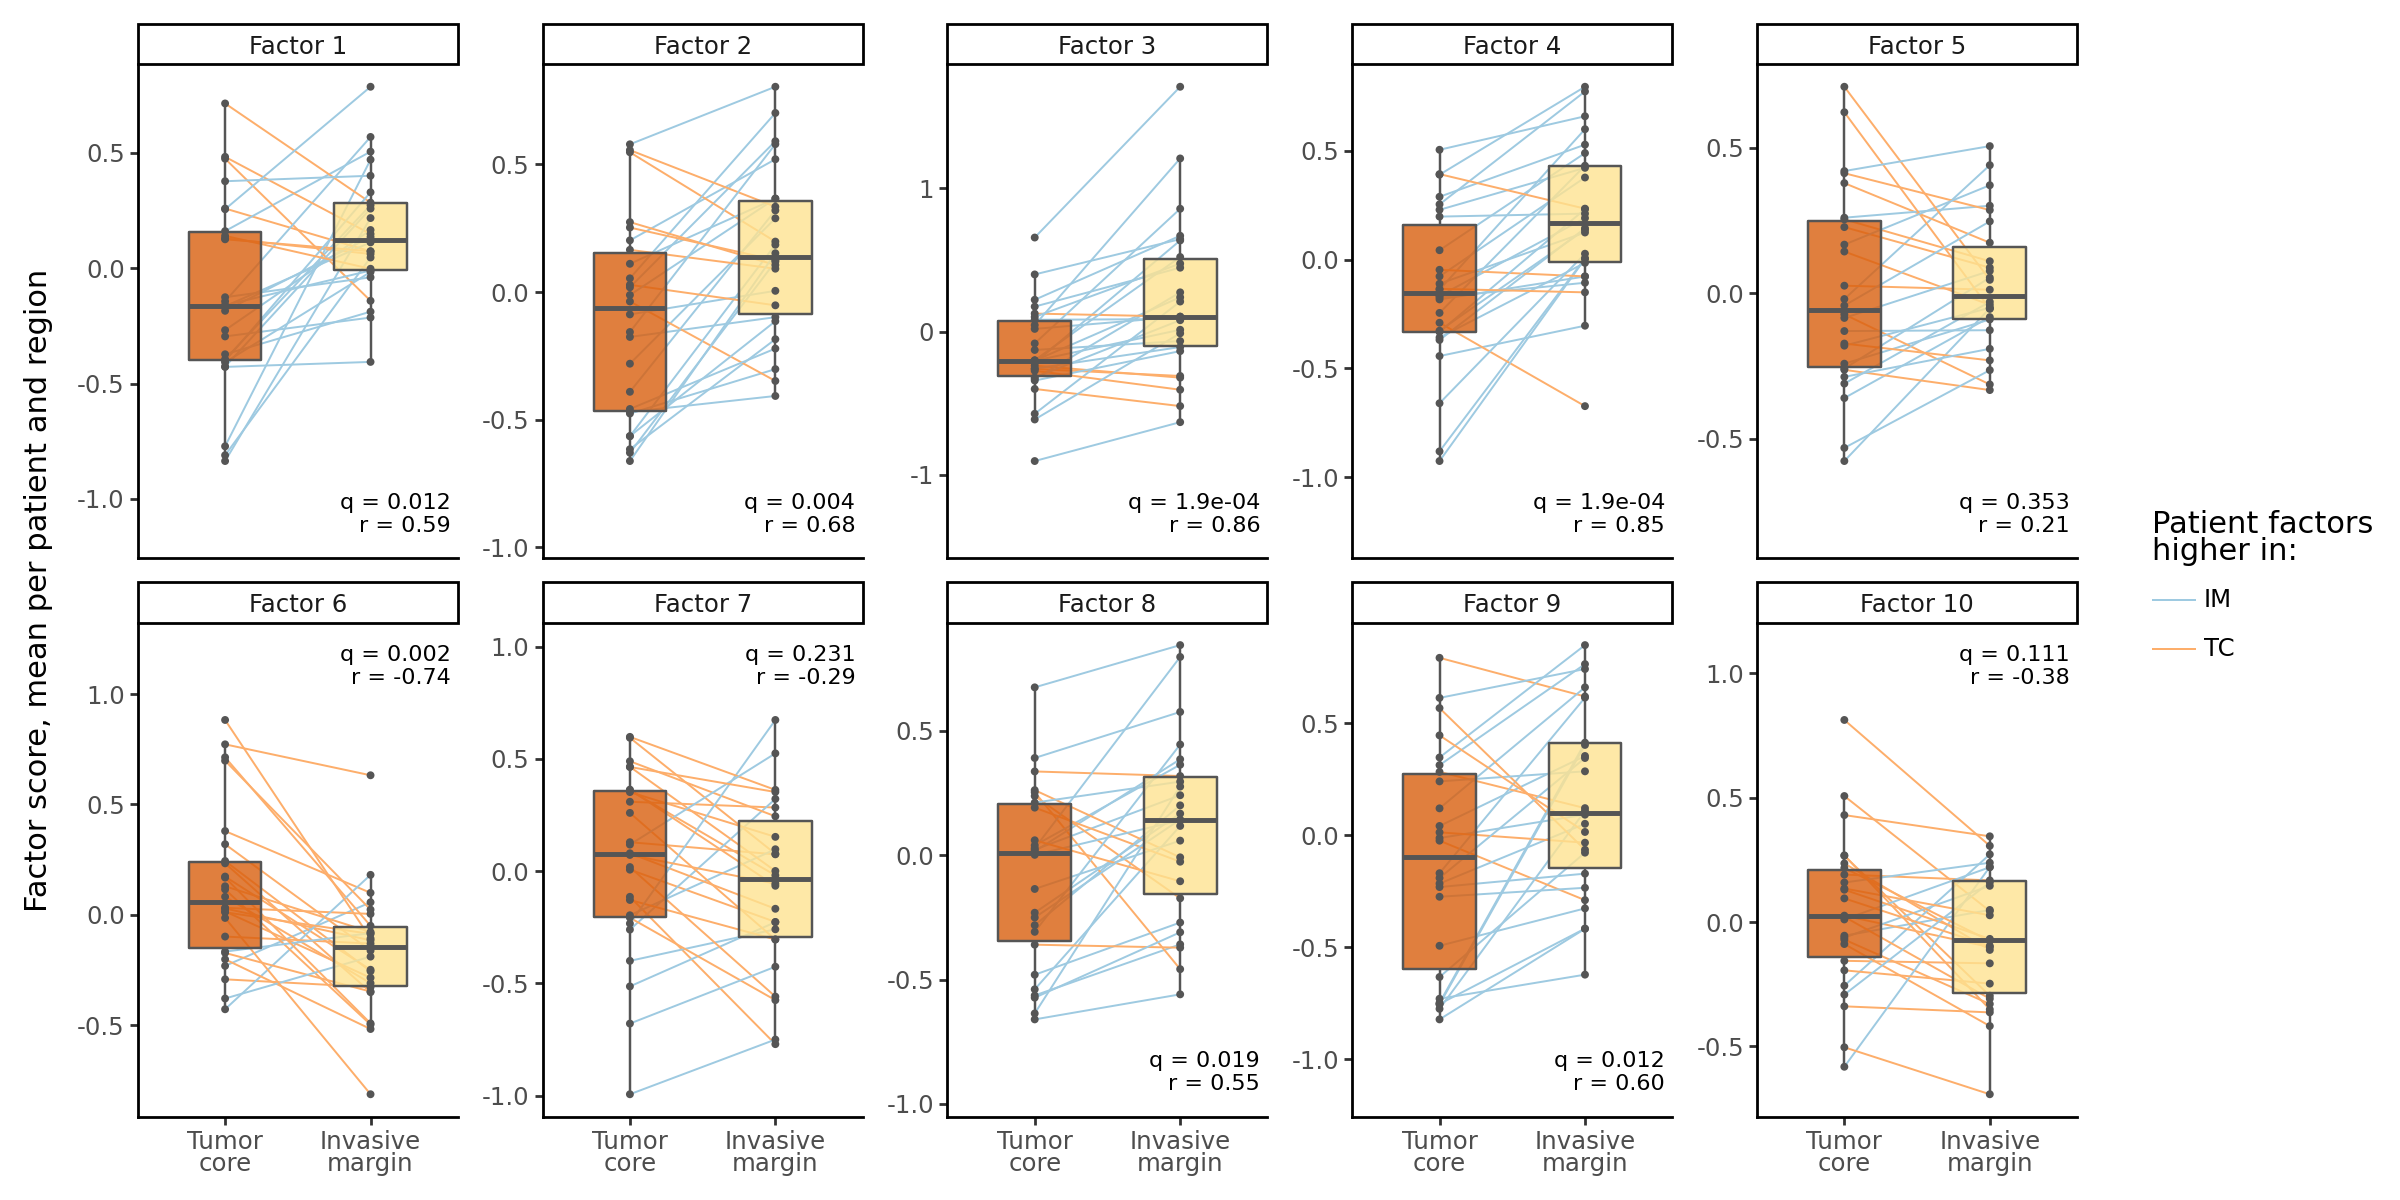

In [17]:
plot_df = per_patient.stack().rename("score").reset_index()
# Direction of each patient's line, from tumor core to invasive margin
difference = (per_patient["IM"] - per_patient["TC"]).dropna()
direction = pd.Series(np.where(difference > 0, "IM", "TC"), index=difference.index, name="direction")
plot_df = plot_df.join(direction, on=["factor", "patient"])
plot_df["direction"] = pd.Categorical(plot_df["direction"], categories=["IM", "TC"])
plot_df["factor"] = pd.Categorical(plot_df["factor"], categories=factor_order)
plot_df["region"] = pd.Categorical(plot_df["region"].map({"TC": "Tumor\ncore", "IM": "Invasive\nmargin"}),
                                   categories=["Tumor\ncore", "Invasive\nmargin"])

def format_q(q):
    return f"q = {q:.1e}" if q < 0.001 else f"q = {q:.3f}"

# Test results per panel, at the invasive margin: below the data when scores are higher
# at the invasive margin, above when lower
region_text = pd.DataFrame({
    "factor": pd.Categorical(factor_order, categories=factor_order),
    "label": [f"{format_q(region_tests.loc[f, 'q (FDR)'])}\nr = {region_tests.loc[f, 'rank-biserial r']:.2f}" for f in factor_order],
    "higher_at_margin": (region_tests.loc[factor_order, "rank-biserial r"] > 0).values,
    "region": "Invasive\nmargin",
})
# With two regions, no corner is free of points: the text is placed beyond the data, at a fifth of the
# panel's range below the lowest score or above the highest, which extends the y axis to make room
value_range = plot_df.groupby("factor", observed=True)["score"].agg(["min", "max"]).loc[factor_order]
text_room = (value_range["max"] - value_range["min"]) / 5
region_text["score"] = np.where(region_text["higher_at_margin"], value_range["min"] - text_room, value_range["max"] + text_room)

# Region colors of AnnotationTransfer.ipynb
region_colors = {"Tumor\ncore": "#d95f0e", "Invasive\nmargin": "#fee391"}
direction_colors = {"IM": "#9ecae1", "TC": "#fdae6b"}
gp = (
    ggplot(plot_df, aes(x="region", y="score"))
    + geom_line(aes(group="patient", color="direction"), size=0.4)
    + geom_boxplot(aes(fill="region"), outlier_shape="", width=0.5, color="#555555", alpha=0.8)
    + geom_point(color="#555555", size=0.6)
    + geom_text(aes(label="label"), data=region_text[region_text["higher_at_margin"]],
                ha="right", va="bottom", nudge_x=0.55, size=8)
    + geom_text(aes(label="label"), data=region_text[~region_text["higher_at_margin"]],
                ha="right", va="top", nudge_x=0.55, size=8)
    + facet_wrap("~factor", ncol=5, scales="free_y")
    + scale_fill_manual(values=region_colors)
    + scale_color_manual(values=direction_colors)
    + guides(fill="none")
    + theme_classic()
    + theme(figure_size=(12, 6))
    + labs(x="", y="Factor score, mean per patient and region", color="Patient factors\nhigher in:")
)
ggsave(gp, figure_dir + "factor_scores_tc_vs_im.pdf", width=12, height=6, verbose=False)
gp

Seven factors differ between the regions at an FDR of 5%. Factors 1, 2, 3, 4, 8 and 9 are higher at the invasive margin, in 19 to 22 of the 26 patients. Factor 6 is lower: only 4 patients have a higher score at the invasive margin. Factors 2, 3, 4 and 6 also pass the Bonferroni correction. Factors 5, 7 and 10 show no difference between the regions.

The same data and tests for Factors 2 and 6, both associated with pT stage in the TMA dataset (`MOFACell.ipynb`), side by side on a common scale, with the regions on the vertical axis.

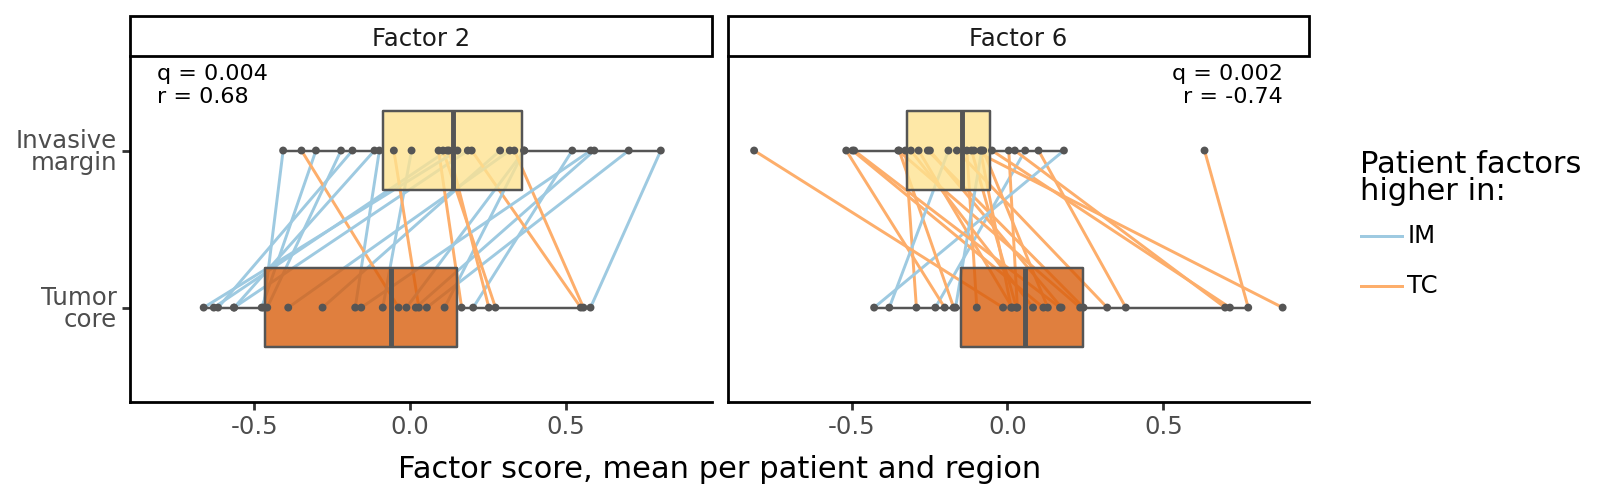

In [18]:
pair_factors = ["Factor 2", "Factor 6"]
pair_df = plot_df[plot_df["factor"].isin(pair_factors)].copy()
pair_df["factor"] = pair_df["factor"].cat.remove_unused_categories()
# Text at the invasive margin, at the top after the flip, on the side left empty by the shift: on the left
# when scores are higher at the invasive margin, on the right when lower. The scale is common to both panels.
pair_text = region_text[region_text["factor"].isin(pair_factors)].copy()
pair_text["factor"] = pair_text["factor"].cat.remove_unused_categories()
pair_text["score"] = np.where(pair_text["higher_at_margin"], pair_df["score"].min(), pair_df["score"].max())

gp = (
    ggplot(pair_df, aes(x="region", y="score"))
    + geom_line(aes(group="patient", color="direction"), size=0.6)
    + geom_boxplot(aes(fill="region"), outlier_shape="", width=0.5, color="#555555", alpha=0.8)
    + geom_point(color="#555555", size=0.6)
    + geom_text(aes(label="label"), data=pair_text[pair_text["higher_at_margin"]],
                ha="left", va="top", nudge_x=0.55, size=8)
    + geom_text(aes(label="label"), data=pair_text[~pair_text["higher_at_margin"]],
                ha="right", va="top", nudge_x=0.55, size=8)
    + facet_wrap("~factor", ncol=2)
    + coord_flip()
    + scale_fill_manual(values=region_colors)
    + scale_color_manual(values=direction_colors)
    + guides(fill="none")
    + theme_classic()
    + theme(figure_size=(8, 2.5), legend_position="right")
    + labs(x="", y="Factor score, mean per patient and region", color="Patient factors\nhigher in:")
)
ggsave(gp, figure_dir + "factor_scores_tc_vs_im_factors_2_6.pdf", width=7.5, height=2, verbose=False)
gp

### Quadrant scores per patient and region
One plot per factor. Each point is a quadrant. Columns are the patients in the order of their number, each with its tumor core then its invasive margin. The fill gives the region and the shape gives the FOV within the patient and region. The plots show how much the scores vary within each patient and region, and how much the patients differ in each region.

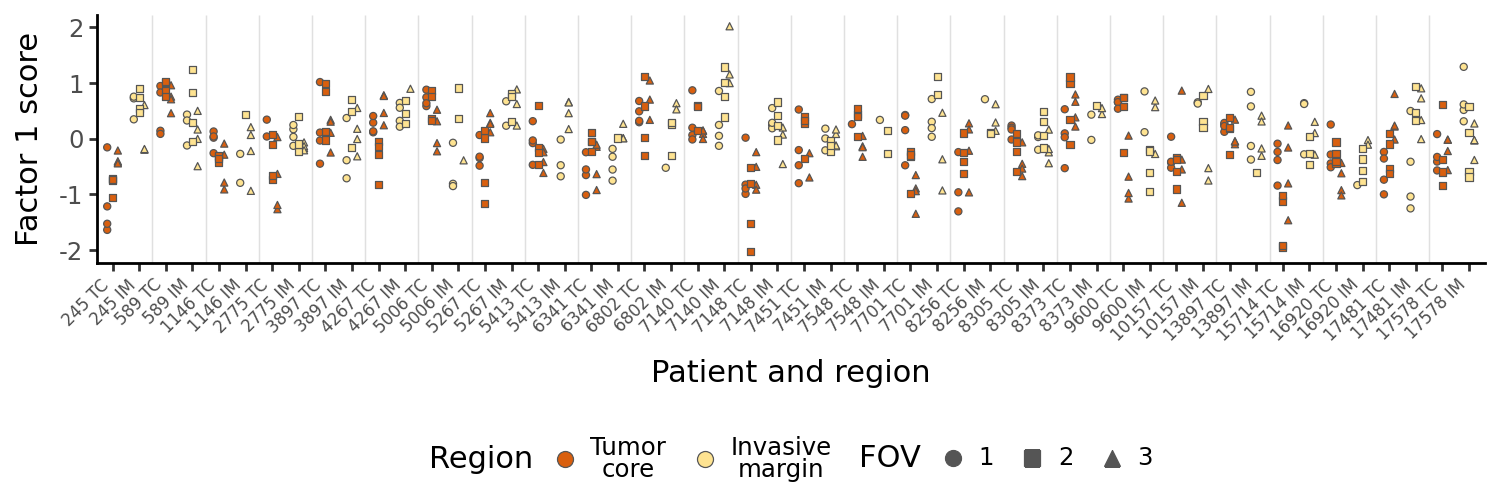

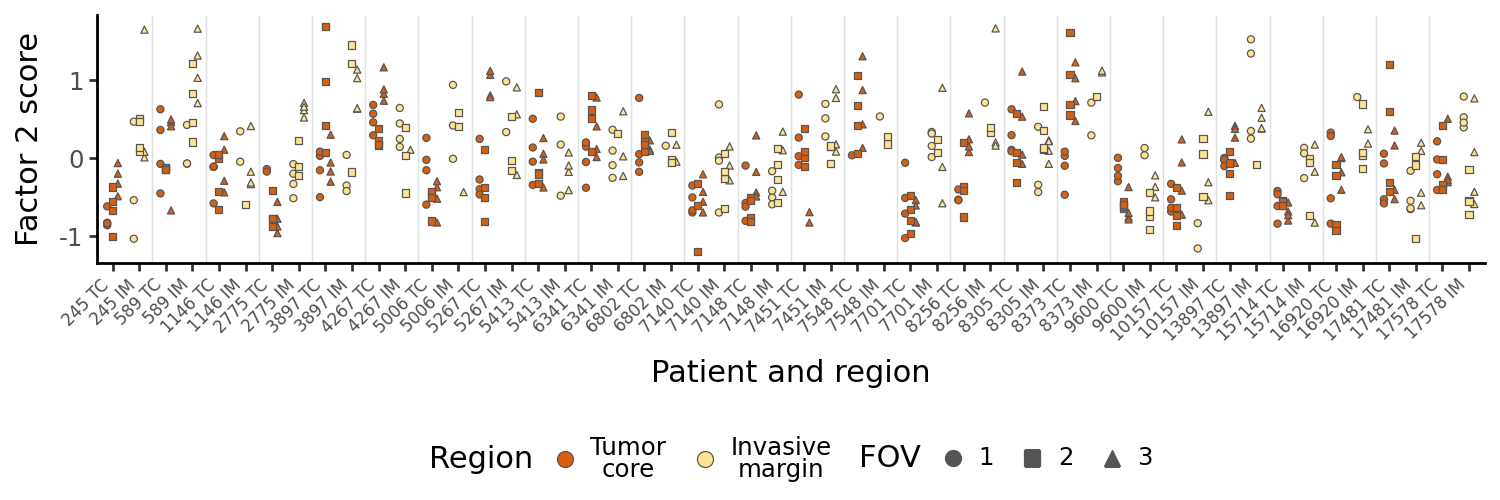

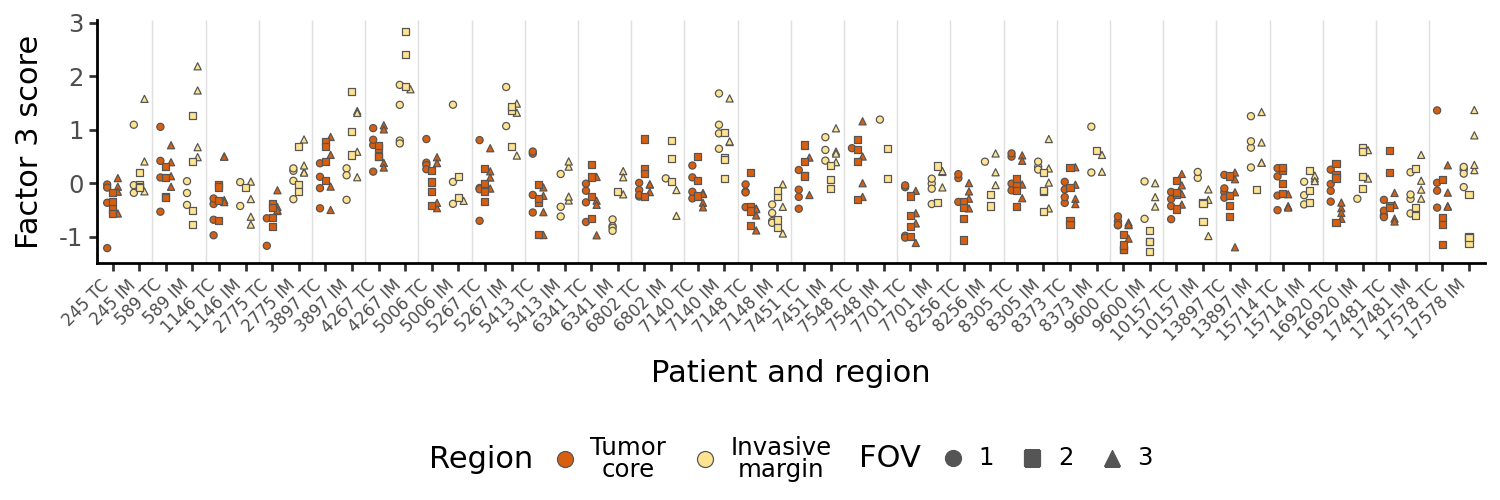

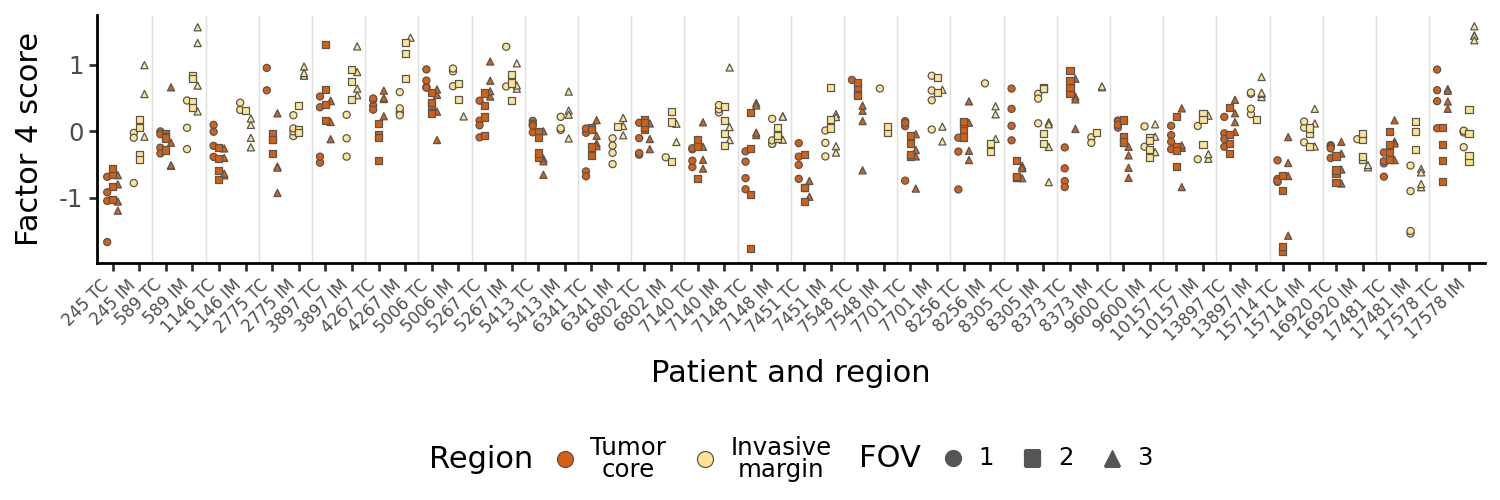

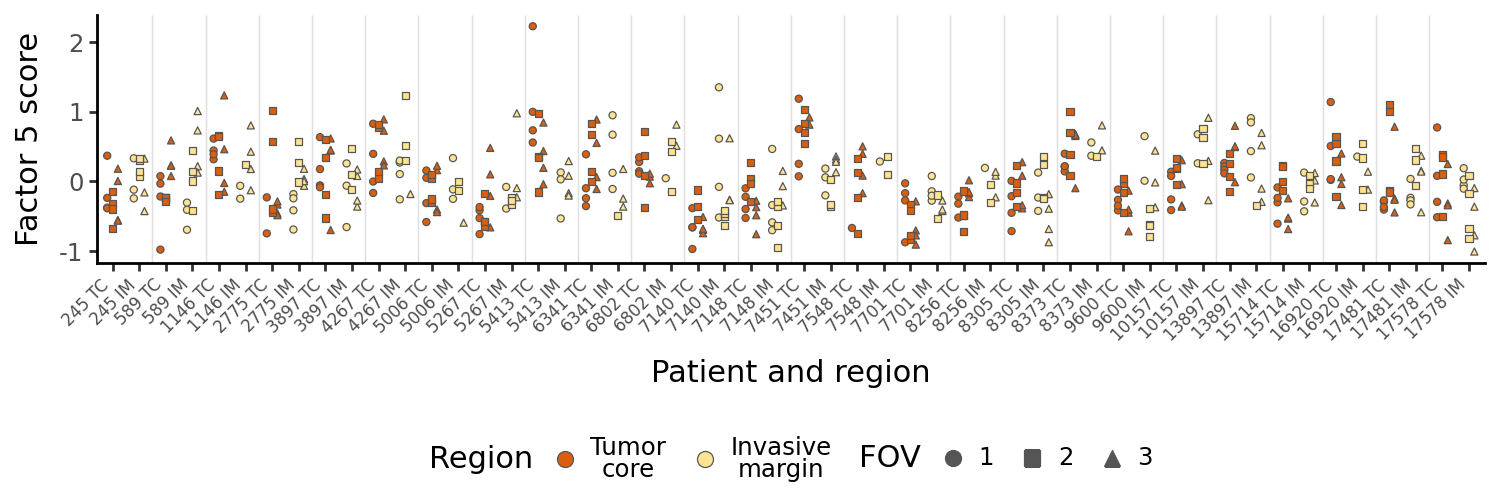

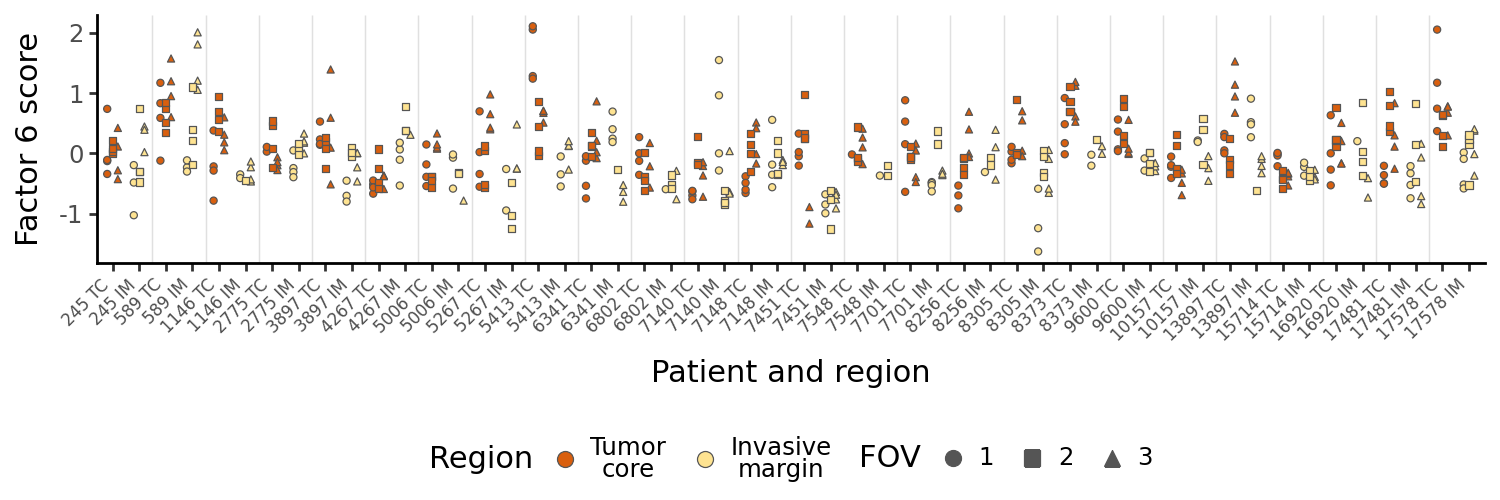

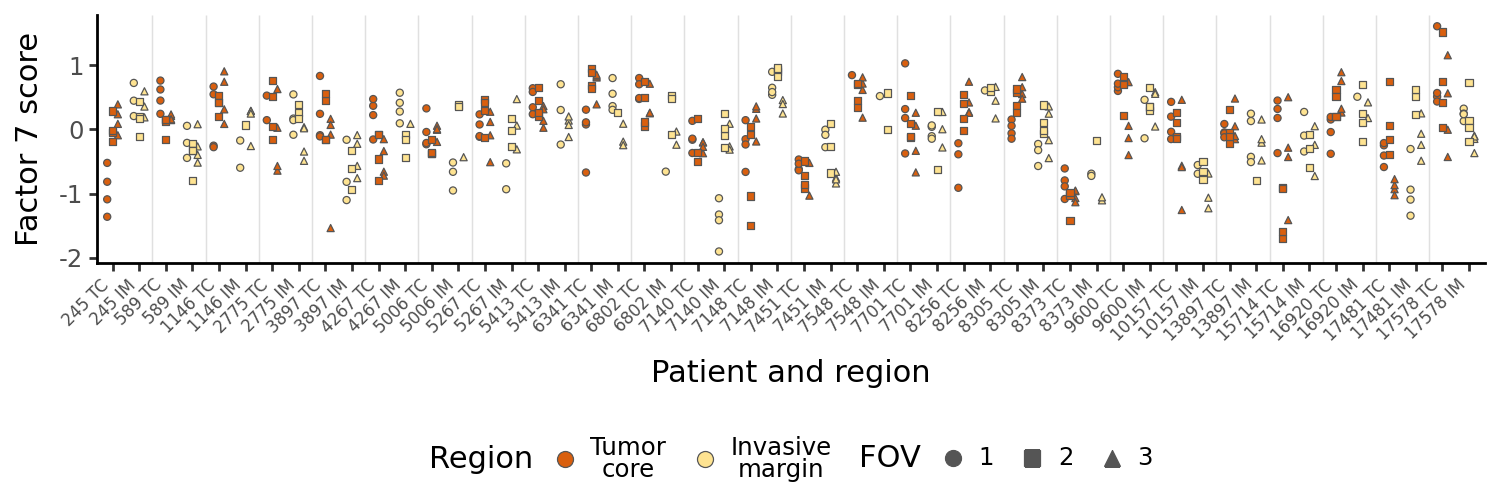

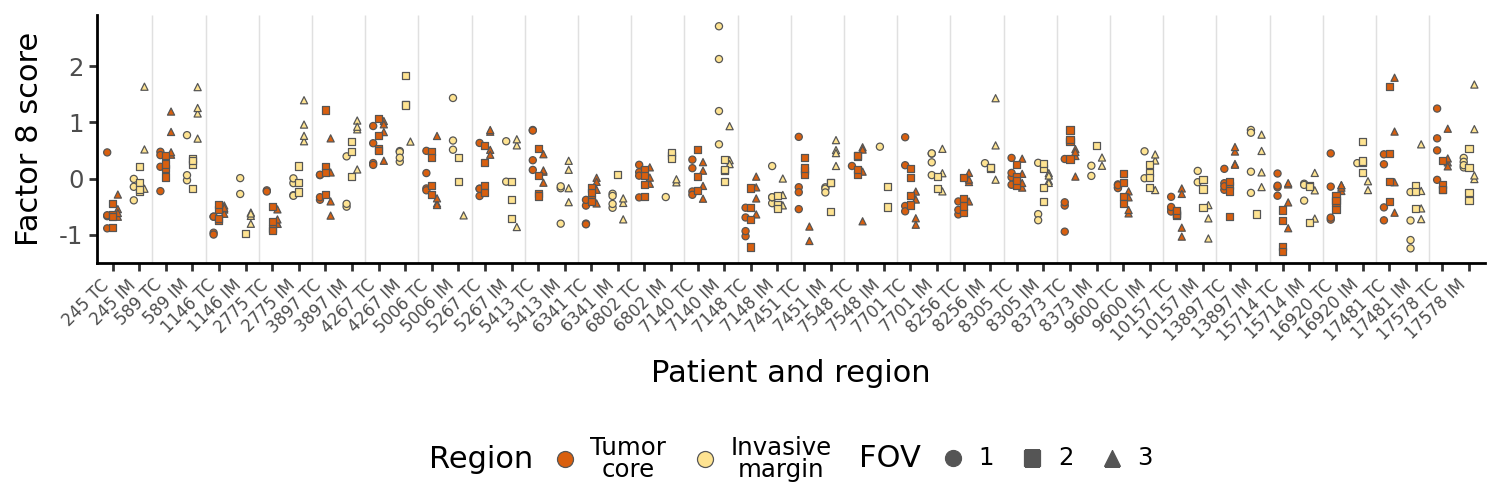

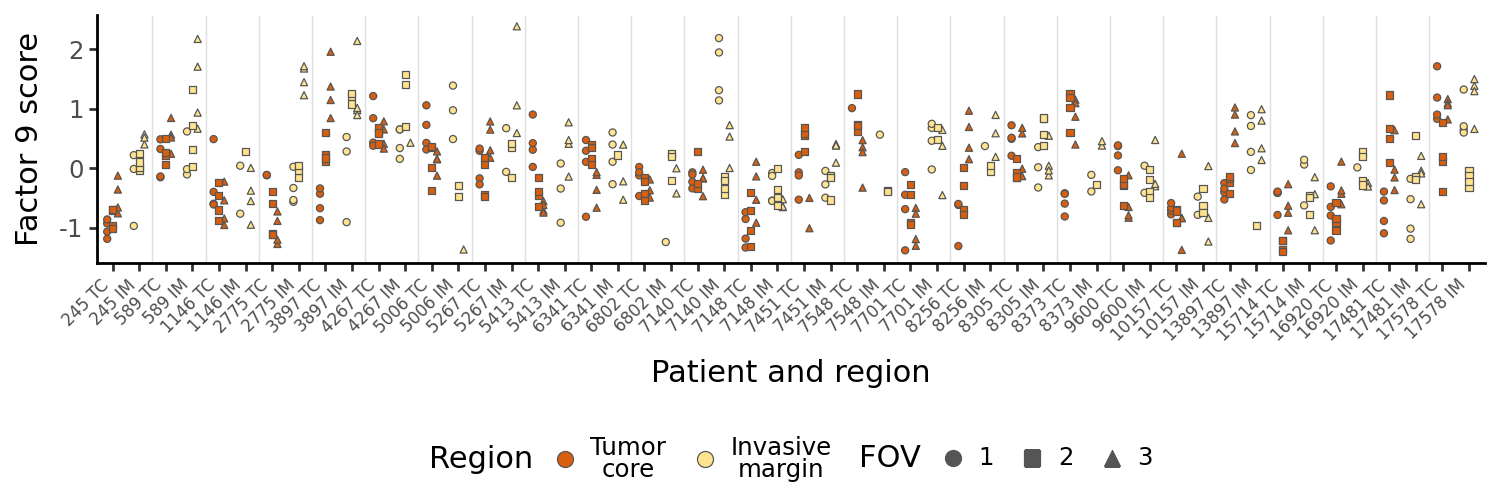

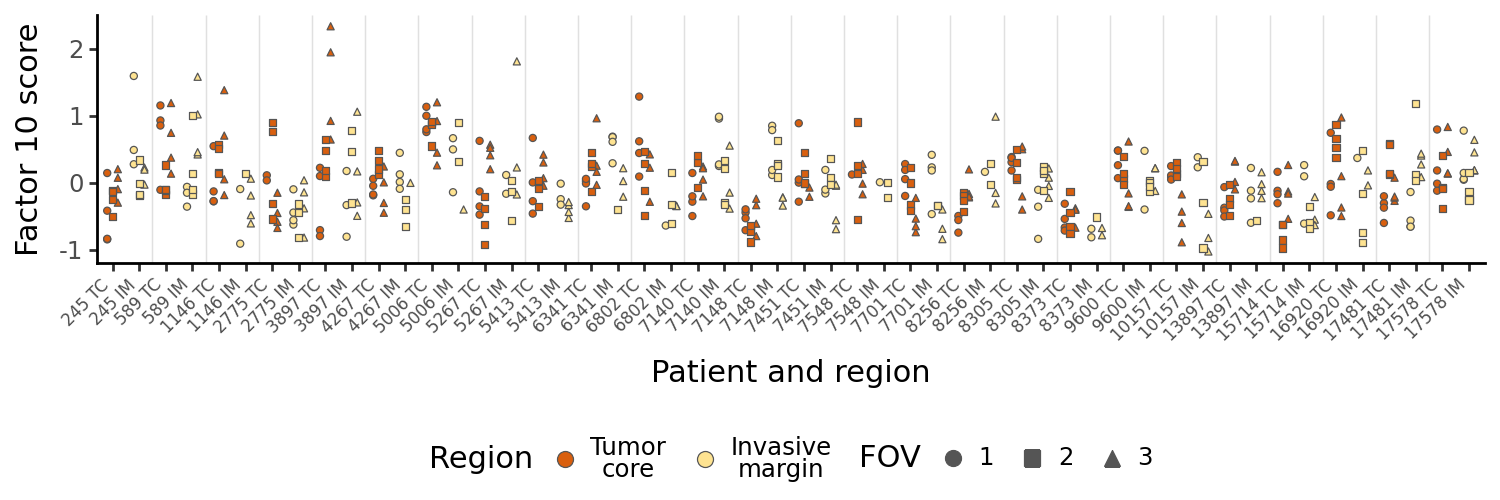

In [19]:
# Columns: patients in the order of their number, tumor core then invasive margin
patient_number = quadrants["patient"].str.extract(r"_(\d+)$", expand=False)
column_order = [f"{p} {r}" for p in sorted(patient_number.unique(), key=int) for r in ["TC", "IM"]]

quadrant_df = new_scores.join(quadrants)
quadrant_df["column"] = pd.Categorical(patient_number + " " + quadrants["region"], categories=column_order)
quadrant_df["region"] = pd.Categorical(quadrants["region"].map({"TC": "Tumor\ncore", "IM": "Invasive\nmargin"}),
                                       categories=list(region_colors))
# FOV number within the patient and region; the "_duplicate1" FOVs fill a missing number
quadrant_df["FOV"] = quadrants["fov"].str.extract(r"_(?:TC|IM)_(\d+)", expand=False)

def quadrant_plot(factor):
    return (
        ggplot(quadrant_df.assign(score=quadrant_df[factor]), aes(x="column", y="score"))
        + geom_vline(xintercept=np.arange(2.5, len(column_order), 2), color="#e0e0e0", size=0.3)  # Between patients
        + geom_point(aes(fill="region", shape="FOV", group="FOV"), position=position_dodge(width=0.6),
                     size=1.2, color="#555555", stroke=0.25)
        + scale_x_discrete()
        + scale_fill_manual(values=region_colors)
        + scale_shape_manual(values=["o", "s", "^"])
        + guides(fill=guide_legend(override_aes={"shape": "o", "size": 3}), shape=guide_legend(override_aes={"size": 3}))
        + theme_classic()
        + theme(axis_text_x=element_text(angle=45, ha="right", size=6), figure_size=(7.5, 2.5), legend_position="bottom")
        + labs(x="Patient and region", y=f"{factor} score", fill="Region", shape="FOV")
    )

os.makedirs(figure_dir + "quadrant_scores/", exist_ok=True)
for factor in factor_order:
    gp = quadrant_plot(factor)
    ggsave(gp, figure_dir + f"quadrant_scores/{factor.replace(' ', '_').lower()}.pdf", width=7.5, height=2.5, verbose=False)
    display(gp)

### Sources of variance
For each factor, a linear mixed model splits the variance of the quadrant scores into five parts:
* **Region**: the mean difference between invasive margin and tumor core, a fixed effect. Its part is the variance of this difference across quadrants.
* **Patient**: how much patients differ, in both regions alike, a random intercept per patient.
* **Patient x region**: how much the difference between regions varies from patient to patient, a random intercept per patient and region.
* **FOV**: how much the FOVs of one patient and region differ, a random intercept per FOV.
* **Quadrant**: how much the quadrants of one FOV differ, the residual.

FOVs are nested within patient and region, so without the patient x region term, a region difference specific to a patient would count as FOV variance. The model is fit by REML with `statsmodels`. The table gives the share of each part, and checks that the parts add up to about the observed variance.

The patient x region part is a property of the tumor: how the patient's levels in the core and at the margin depart from the cohort shift. The figures add it to the patient part, which then gives how much patients differ within one region.

In [20]:
def variance_components(factor):
    """Variance of the quadrant scores of a factor, from a linear mixed model fit by REML"""
    df = quadrant_df.assign(score=quadrant_df[factor], region=quadrants["region"])
    model = smf.mixedlm("score ~ C(region, Treatment('TC'))", df, groups="patient", re_formula="1",
                        vc_formula={"patient_region": "0 + C(region)", "fov": "0 + C(fov)"})
    fit = model.fit(reml=True, method=["lbfgs", "powell"])
    vc = dict(zip(model.exog_vc.names, fit.vcomp))
    # Variance of the fitted region difference across quadrants
    region_term = fit.fe_params.iloc[1] * (df["region"] == "IM")
    return pd.Series({
        "Region": region_term.var(ddof=0),
        "Patient": fit.cov_re.iloc[0, 0],
        "Patient x region": vc["patient_region"],
        "FOV": vc["fov"],
        "Quadrant": fit.scale,
        "converged": fit.converged,
    })

components = pd.DataFrame({factor: variance_components(factor) for factor in factor_order}).T
assert components.pop("converged").all()
components = components.astype(float)
variance_shares = components.div(components.sum(axis=1), axis=0)
# The components should add up to about the observed variance of the quadrant scores
variance_shares.assign(**{"sum of components": components.sum(axis=1), "observed variance": new_scores[factor_order].var()}).round(3)

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.


,Region,Patient,Patient x region,FOV,Quadrant,sum of components,observed variance
Factor 1,0.057,0.045,0.188,0.268,0.441,0.331,0.331
Factor 2,0.058,0.205,0.086,0.230,0.421,0.297,0.294
Factor 3,0.083,0.302,0.089,0.136,0.390,0.396,0.378
Factor 4,0.095,0.260,0.048,0.308,0.289,0.291,0.286
Factor 5,0.001,0.184,0.098,0.139,0.579,0.212,0.211
Factor 6,0.073,0.119,0.075,0.370,0.363,0.286,0.287
Factor 7,0.008,0.230,0.149,0.273,0.340,0.300,0.294
Factor 8,0.028,0.207,0.075,0.253,0.437,0.310,0.311
Factor 9,0.031,0.228,0.021,0.470,0.250,0.470,0.476
Factor 10,0.007,0.100,0.085,0.296,0.512,0.242,0.241


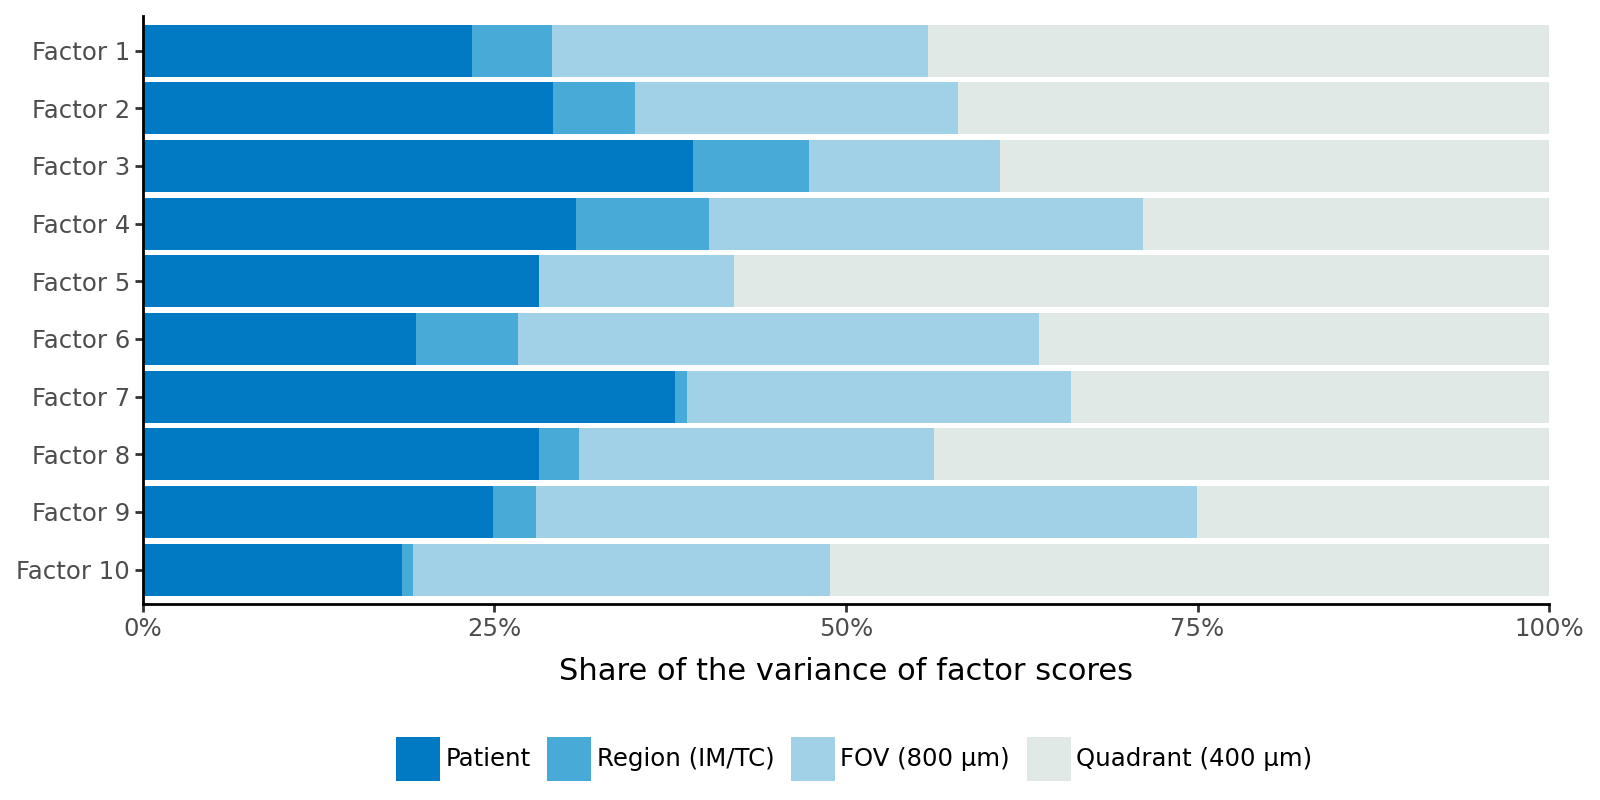

In [21]:
# Patient x region is added to the patient part: together, how much patients differ within one region
figure_shares = (variance_shares.assign(Patient=variance_shares["Patient"] + variance_shares["Patient x region"])
                 .rename(columns={"Region": "Region (IM/TC)", "FOV": "FOV (800 µm)", "Quadrant": "Quadrant (400 µm)"}))
# From the largest scale to the smallest, from left to right
component_colors = {"Patient": "#027AC3", "Region (IM/TC)": "#48AAD6", "FOV (800 µm)": "#A0D1E7", "Quadrant (400 µm)": "#E0E9E6"}
figure_shares = figure_shares[list(component_colors)]

def variance_plot(factors, height):
    share_df = figure_shares.loc[factors].rename_axis("factor").reset_index().melt(id_vars="factor", var_name="component", value_name="share")
    share_df["factor"] = pd.Categorical(share_df["factor"], categories=factors[::-1])
    share_df["component"] = pd.Categorical(share_df["component"], categories=list(component_colors)[::-1])
    return (
        ggplot(share_df, aes(x="factor", y="share", fill="component"))
        + geom_col()
        + coord_flip()
        + scale_fill_manual(values=component_colors)
        + guides(fill=guide_legend(reverse=True))
        + scale_y_continuous(labels=lambda breaks: [f"{b:.0%}" for b in breaks], expand=(0, 0))
        + theme_classic()
        + theme(legend_position="bottom", figure_size=(8, height))
        + labs(x="", y="Share of the variance of factor scores", fill="")
    )

gp = variance_plot(factor_order, 4)
ggsave(gp, figure_dir + "variance_components.pdf", width=8, height=4, verbose=False)
gp

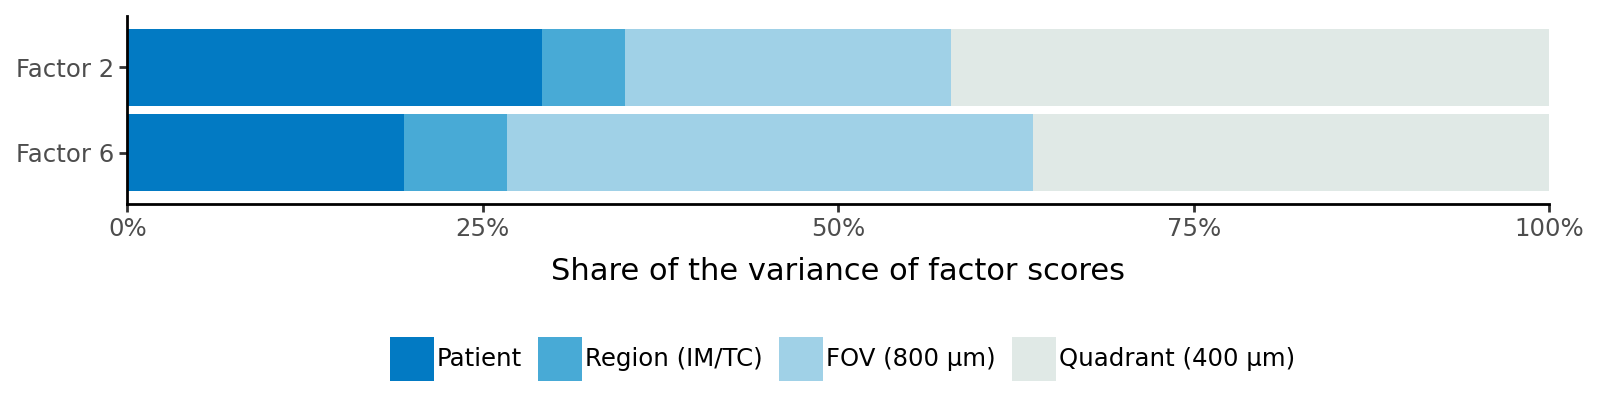

In [22]:
gp = variance_plot(["Factor 2", "Factor 6"], 2)
ggsave(gp, figure_dir + "variance_components_factors_2_6.pdf", width=7.5, height=2, verbose=False)
gp

### Precision of one reading
A reading is the mean score of one quadrant, the size of a TMA FOV, or of one FOV of 4 quadrants. From the variance parts of each factor:
* **Patient SD**: the square root of the patient and patient x region parts, how much the true levels of patients differ within one region.
* **Noise**: the SD of one reading around the true level of its patient and region. For one quadrant, the FOV and quadrant parts add up. For one FOV, the quadrant part is divided by 4.
* **Detectable shift**: 1.96 times the noise, the smallest distance from the cohort center at which the 95% confidence interval of one reading excludes the center.

Noise and shifts are in units of the patient SD. With k readings, both are divided by the square root of k, assuming the readings are taken in distinct places of the tumor.

In [23]:
patient_variance = components["Patient"] + components["Patient x region"]
reading_variance = {"quadrant": components["FOV"] + components["Quadrant"],
                    "FOV": components["FOV"] + components["Quadrant"] / 4}

reading_precision = pd.DataFrame({"patient SD": np.sqrt(patient_variance)})
for reading, variance in reading_variance.items():
    reading_precision[f"noise of one {reading}, in patient SD"] = np.sqrt(variance / patient_variance)
for reading, variance in reading_variance.items():
    reading_precision[f"detectable shift with one {reading}, in patient SD"] = norm.ppf(0.975) * np.sqrt(variance / patient_variance)
reading_precision.rename_axis("factor").to_csv(data_dir + "sampling/factor_reading_precision.csv")
reading_precision.round(2)

,patient SD,"noise of one quadrant, in patient SD","noise of one FOV, in patient SD","detectable shift with one quadrant, in patient SD","detectable shift with one FOV, in patient SD"
Factor 1,0.28,1.74,1.27,3.41,2.49
Factor 2,0.29,1.49,1.07,2.93,2.10
Factor 3,0.39,1.16,0.77,2.27,1.51
Factor 4,0.30,1.39,1.11,2.73,2.18
Factor 5,0.24,1.60,1.00,3.13,1.97
Factor 6,0.24,1.94,1.54,3.81,3.02
Factor 7,0.34,1.27,0.97,2.49,1.91
Factor 8,0.30,1.56,1.13,3.07,2.22
Factor 9,0.34,1.70,1.46,3.33,2.87
Factor 10,0.21,2.09,1.52,4.10,2.97


### Readings needed to place a patient closer to a clinical group
Each clinical variable is paired with its two factors, as in `FactorClinical.ipynb`, and split into two groups of the TMA dataset: pT1-2 and pT3-4 for Factors 2 and 6, pN0 and pN1-2 for Factors 5 and 8, MSS and MSI for Factors 3 and 9. The shift between the groups is the difference of their mean scores in the TMA FOVs, which share the scale of the quadrant scores since both are projections on the same loadings.

A patient whose true level sits at the mean of one group is placed with confidence when the mean of its readings falls on the side of this group, past the midpoint between the group means, with 95% probability. With two factors, the distance between the groups is the Mahalanobis distance under the noise covariance of one reading, which k readings divide by k. The number of readings needed is (2 x 1.645)² over the squared distance, for both factors together and for each one alone.

The accuracy is the share of patients that the same midpoint rule assigns to their own group, with both groups weighted equally: with one quadrant, with 3 FOVs as in this dataset, and with a perfectly measured patient. The last one shows how much the groups overlap, whatever the sampling.

The covariances between the two factors are estimated by moments: between quadrants of a FOV, between FOVs of a patient and region, and between patients within a region, each corrected for the noise of the levels below.

In [24]:
def covariance_within(df, keys, columns):
    """Covariance of the columns around the means of the groups defined by keys, one degree of freedom lost per group"""
    deviations = df[columns] - df.groupby(keys)[columns].transform("mean")
    return (deviations.T @ deviations).values / (len(df) - df.groupby(keys).ngroups)

def covariance_levels(factors):
    """Covariances of factor scores at the quadrant, FOV and patient level, estimated by moments"""
    scores = new_scores[factors].join(quadrants)
    quadrants_per_fov = 1 / (1 / scores.groupby("fov").size()).mean()  # harmonic mean
    fovs_per_region = 1 / (1 / scores.groupby(["patient", "region"])["fov"].nunique()).mean()
    quadrant_level = covariance_within(scores, ["fov"], factors)
    fov_means = scores.groupby(["patient", "region", "fov"])[factors].mean().reset_index()
    fov_level = covariance_within(fov_means, ["patient", "region"], factors) - quadrant_level / quadrants_per_fov
    region_means = scores.groupby(["patient", "region"])[factors].mean().reset_index()
    patient_level = (covariance_within(region_means, ["region"], factors)
                     - fov_level / fovs_per_region - quadrant_level / (fovs_per_region * quadrants_per_fov))
    return quadrant_level, fov_level, patient_level

def squared_distance(shift, covariance):
    return shift @ np.linalg.solve(covariance, shift)

# File of TMA factor scores, column of the groups, the two groups, and the factors of each clinical variable
clinical_groups = {
    "pT": ("factor_scores.csv", "Stage", ["pT1", "pT2"], ["pT3", "pT4"], ["Factor 2", "Factor 6"]),
    "pN": ("pN_factor_scores.csv", "Node", ["pN0"], ["pN1", "pN2"], ["Factor 5", "Factor 8"]),
    "MSI": ("MSI_factor_scores.csv", "MS", ["MSS"], ["MSI"], ["Factor 3", "Factor 9"]),
}
z = norm.ppf(0.95)
group_readings = []
for variable, (file, column, groups_1, groups_2, pair) in clinical_groups.items():
    tma = pd.read_csv(data_dir + file)
    group_1, group_2 = tma[tma[column].isin(groups_1)], tma[tma[column].isin(groups_2)]
    quadrant_level, fov_level, patient_level = covariance_levels(pair)
    # The moment estimates should agree with the mixed model
    assert np.allclose(np.diag(patient_level), patient_variance[pair], rtol=0.1), variable
    one_reading = {"quadrant": fov_level + quadrant_level, "FOV": fov_level + quadrant_level / 4}
    for factors in [pair, pair[:1], pair[1:]]:
        keep = np.ix_([pair.index(f) for f in factors], [pair.index(f) for f in factors])
        shift = (group_2[factors].mean() - group_1[factors].mean()).values
        patient_sd = np.sqrt(np.diag(patient_level[keep]))
        group_readings.append({
            "variable": variable,
            "groups": f"{'/'.join(groups_1)} vs {'/'.join(groups_2)}",
            "TMA FOVs per group": f"{len(group_1)}, {len(group_2)}",
            "factors": " + ".join(factors),
            "shift, in patient SD": ", ".join(f"{s:+.2f}" for s in shift / patient_sd),
            "quadrants needed": (2 * z) ** 2 / squared_distance(shift, one_reading["quadrant"][keep]),
            "FOVs needed": (2 * z) ** 2 / squared_distance(shift, one_reading["FOV"][keep]),
            "accuracy, 1 quadrant": norm.cdf(np.sqrt(squared_distance(shift, patient_level[keep] + one_reading["quadrant"][keep])) / 2),
            "accuracy, 3 FOVs": norm.cdf(np.sqrt(squared_distance(shift, patient_level[keep] + one_reading["FOV"][keep] / 3)) / 2),
            "accuracy, perfect measurement": norm.cdf(np.sqrt(squared_distance(shift, patient_level[keep])) / 2),
        })
group_readings = pd.DataFrame(group_readings)
group_readings.to_csv(data_dir + "sampling/clinical_group_readings.csv", index=False)
group_readings.round(2)

,variable,groups,TMA FOVs per group,factors,"shift, in patient SD",quadrants needed,FOVs needed,"accuracy, 1 quadrant","accuracy, 3 FOVs","accuracy, perfect measurement"
0,pT,pT1/pT2 vs pT3/pT4,"103, 315",Factor 2 + Factor 6,"-0.77, -1.03",26.80,16.43,0.61,0.67,0.73
1,pT,pT1/pT2 vs pT3/pT4,"103, 315",Factor 2,-0.77,40.10,20.67,0.59,0.63,0.65
2,pT,pT1/pT2 vs pT3/pT4,"103, 315",Factor 6,-1.03,40.27,24.91,0.59,0.65,0.70
3,pN,pN0 vs pN1/pN2,"222, 194",Factor 5 + Factor 8,"-0.52, +0.53",31.63,14.79,0.59,0.63,0.65
4,pN,pN0 vs pN1/pN2,"222, 194",Factor 5,-0.52,104.79,41.53,0.55,0.59,0.60
5,pN,pN0 vs pN1/pN2,"222, 194",Factor 8,+0.53,94.71,50.35,0.56,0.59,0.60
6,MSI,MSS vs MSI,"314, 17",Factor 3 + Factor 9,"+1.20, +1.72",7.01,3.90,0.68,0.75,0.80
7,MSI,MSS vs MSI,"314, 17",Factor 3,+1.20,9.61,4.16,0.65,0.71,0.73
8,MSI,MSS vs MSI,"314, 17",Factor 9,+1.72,11.29,8.41,0.66,0.74,0.80


## Export

In [25]:
export = quadrants.join(new_scores).join(n_observed.rename("n_features_observed"))
export.rename_axis("fov_quadrant").to_csv(data_dir + "sampling/muvi_factor_scores_quadrants.csv")

# Unstandardised features of the new quadrants, with the views and feature names of the reference
features_mdata = mu.MuData({view: mu.AnnData(X) for view, X in new_features.items()})
features_mdata.obs = features_mdata.obs.join(quadrants)
features_mdata.write_h5mu(data_dir + "sampling/celltype_features_quadrants.h5mu")

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:931: UserWarning: Cannot join columns with the same name because var_names are intersecting.
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:1429: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
... storing 'fov' as categorical
... storing 'patient'